# Stock Depletion & Replenishment Prediction

Tujuan: memprediksi **kapan stok produk akan habis**, per outlet dan per item.

- Sumber data: `data/Stock.csv` (buku stok harian 3 outlet x 94 item, 272 hari)
- Target utama (aksi replenishment): **hari sampai `ClosingStock` turun di bawah `MinimumStock`**
- Target kedua (stok benar-benar kosong): **hari sampai `ClosingStock` = 0**
- Model pembanding: tiga model yang sama dengan notebook *demand* dan *sales*
  **SARIMA**, **ETS (Holt-Winters)**, **Gradient Boosting**
- Pemilihan model: MAE hari terbaik, dengan MAE permintaan sebagai penentu kedua
- Output: tabel prioritas replenishment per item, model terbaik disimpan sebagai `.pkl`

Cara kerja: model meramal **permintaan harian (`StockOut`)** untuk 28 hari ke depan, lalu ramalan itu
dikurangi bertahap dari stok terakhir sampai melewati ambang. Jadi pertanyaannya berubah dari
"berapa item terjual besok" menjadi "berapa hari lagi stok ini perlu diisi".

Hasil disimpan di `artifacts/stock_depletion/`.

## 1. Konfigurasi

In [1]:
import json
import pickle
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

DATA_PATH = Path("..") / "data" / "Stock.csv"
OUTPUT_DIR = Path("..") / "artifacts" / "stock_depletion"
MODEL_PATH = OUTPUT_DIR / "model.pkl"
METADATA_PATH = OUTPUT_DIR / "metadata.json"

TEST_DAYS = 28      # hari terakhir tiap seri dipakai sebagai data uji
SEASON_LENGTH = 7   # pola mingguan
HORIZON = 28        # panjang ramalan permintaan
SEED = 42

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

print("pandas      :", pd.__version__)
print("folder hasil:", OUTPUT_DIR.resolve())

C:\Users\Radit\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
C:\Users\Radit\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


pandas      : 3.0.3
folder hasil: C:\Users\Radit\Politeknik Negeri Malang\Semester 5\ProjectBasedLearning_MyVentory\ML\artifacts\stock_depletion


## 2. Memuat buku stok dan memeriksa konsistensinya

Sebelum dipakai, neraca stok diuji: `OpeningStock + StockIn - StockOut` harus sama dengan `ClosingStock`
pada setiap baris.

In [2]:
stock = pd.read_csv(DATA_PATH, parse_dates=["Date"])
stock = stock.sort_values(["Outlet", "ItemID", "Date"]).reset_index(drop=True)

ledger_ok = (stock.OpeningStock + stock.StockIn - stock.StockOut == stock.ClosingStock).all()

print(f"baris data      : {len(stock):,}")
print(f"outlet          : {sorted(stock.Outlet.unique())}")
print(f"jumlah item     : {stock.ItemID.nunique()}")
print(f"jumlah seri     : {stock.groupby(['Outlet', 'ItemID']).ngroups} (outlet x item)")
print(f"rentang tanggal : {stock.Date.min().date()} s/d {stock.Date.max().date()} ({stock.Date.nunique()} hari)")
print(f"neraca stok valid: {bool(ledger_ok)}")
print()
print(stock.describe().round(2).to_string())

baris data      : 76,704
outlet          : ['SHOP001', 'SHOP002', 'SHOP003']
jumlah item     : 94
jumlah seri     : 282 (outlet x item)
rentang tanggal : 2025-01-02 s/d 2025-09-30 (272 hari)
neraca stok valid: True

                      Date  OpeningStock   StockIn  StockOut  ClosingStock  MinimumStock
count                76704      76704.00  76704.00  76704.00      76704.00      76704.00
mean   2025-05-17 12:00:00          4.47      0.76      0.78          4.45          2.70
min    2025-01-02 00:00:00          0.00      0.00      0.00          0.00          1.00
25%    2025-03-10 18:00:00          3.00      0.00      0.00          3.00          2.00
50%    2025-05-17 12:00:00          4.00      0.00      1.00          4.00          2.50
75%    2025-07-24 06:00:00          6.00      0.00      1.00          6.00          3.00
max    2025-09-30 00:00:00         20.00     17.00      7.00         19.00          6.00
std                    NaN          2.79      2.21      0.92          2.

In [3]:
stockout_rate = (stock.ClosingStock == 0).mean()
restock_rate = (stock.StockIn > 0).mean()

ins = stock[stock.StockIn > 0]
gap = ins.groupby(["Outlet", "ItemID"]).Date.apply(lambda series: series.diff().dt.days.dropna().median())

print(f"hari dengan stok kosong : {(stock.ClosingStock == 0).sum():,} ({stockout_rate:.1%})")
print(f"hari dengan barang masuk: {len(ins):,} ({restock_rate:.1%})")
print(f"selang restock median   : {gap.median():.0f} hari")
print(f"level stok setelah restock (median): {ins.ClosingStock.median():.0f} unit")
print()
print("Artinya pengisian stok berjalan rutin tiap sekitar seminggu, dan stok yang dipegang")
print("kecil (median 4 unit). Karena itu 'stok habis' sangat ditentukan oleh ritme restock,")
print("bukan hanya oleh besarnya permintaan.")

hari dengan stok kosong : 4,227 (5.5%)
hari dengan barang masuk: 9,597 (12.5%)
selang restock median   : 7 hari
level stok setelah restock (median): 6 unit

Artinya pengisian stok berjalan rutin tiap sekitar seminggu, dan stok yang dipegang
kecil (median 4 unit). Karena itu 'stok habis' sangat ditentukan oleh ritme restock,
bukan hanya oleh besarnya permintaan.


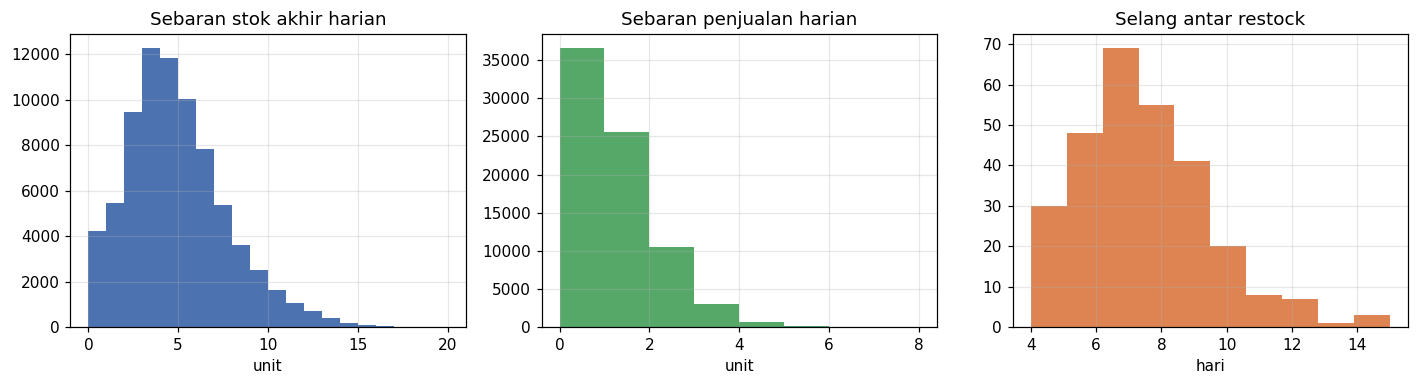

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))

axes[0].hist(stock.ClosingStock, bins=range(0, 21), color="#4c72b0")
axes[0].set_title("Sebaran stok akhir harian")
axes[0].set_xlabel("unit")

axes[1].hist(stock.StockOut, bins=range(0, 9), color="#55a868")
axes[1].set_title("Sebaran penjualan harian")
axes[1].set_xlabel("unit")

axes[2].hist(gap.dropna(), bins=10, color="#dd8452")
axes[2].set_title("Selang antar restock")
axes[2].set_xlabel("hari")

fig.tight_layout()
fig.savefig(OUTPUT_DIR / "fig_1_distribution.png", dpi=120)
plt.show()

## 3. Membagi data dan menetapkan target sebenarnya

28 hari terakhir setiap seri menjadi data uji. Target sebenarnya dihitung dari buku stok:
hari pertama `ClosingStock` turun di bawah `MinimumStock`, dan hari pertama `ClosingStock` menjadi 0.
Nilai 29 berarti "tidak terjadi dalam 28 hari".

In [5]:
cutoff = stock.Date.max() - pd.Timedelta(days=TEST_DAYS)

state_rows = []
for (outlet, item), group in stock.groupby(["Outlet", "ItemID"]):
    group = group.sort_values("Date")
    train = group[group.Date <= cutoff]
    test = group[group.Date > cutoff]

    below_days = test[test.ClosingStock < test.MinimumStock].Date
    zero_days = test[test.ClosingStock == 0].Date

    state_rows.append({
        "Outlet": outlet,
        "ItemID": item,
        "start_stock": float(train.ClosingStock.iloc[-1]),
        "min_stock": float(train.MinimumStock.iloc[-1]),
        "actual_days_below": (below_days.iloc[0] - cutoff).days if len(below_days) else HORIZON + 1,
        "actual_days_zero": (zero_days.iloc[0] - cutoff).days if len(zero_days) else HORIZON + 1,
    })

state = pd.DataFrame(state_rows)

print(f"batas data latih : s/d {cutoff.date()}")
print(f"batas data uji   : {cutoff.date() + pd.Timedelta(days=1)} s/d {stock.Date.max().date()}")
print(f"seri dianalisis  : {len(state)}")
print()
print(f"seri yang turun di bawah minimum dalam 28 hari : {(state.actual_days_below <= HORIZON).sum()} "
      f"({(state.actual_days_below <= HORIZON).mean():.1%})")
print(f"seri yang stoknya habis dalam 28 hari          : {(state.actual_days_zero <= HORIZON).sum()} "
      f"({(state.actual_days_zero <= HORIZON).mean():.1%})")
print()
print(state[["start_stock", "min_stock", "actual_days_below", "actual_days_zero"]].describe().round(1).to_string())

batas data latih : s/d 2025-09-02
batas data uji   : 2025-09-03 s/d 2025-09-30
seri dianalisis  : 282

seri yang turun di bawah minimum dalam 28 hari : 251 (89.0%)
seri yang stoknya habis dalam 28 hari          : 148 (52.5%)

       start_stock  min_stock  actual_days_below  actual_days_zero
count        282.0      282.0              282.0             282.0
mean           4.5        2.7                9.4              19.3
std            2.7        1.1                9.2              10.8
min            0.0        1.0                1.0               1.0
25%            3.0        2.0                3.0               8.0
50%            4.0        2.5                5.5              25.0
75%            6.0        3.0               13.8              29.0
max           18.0        6.0               29.0              29.0


## 4. Melatih tiga model per seri dan menurunkan waktu habis

Untuk setiap seri dijalankan tiga model yang sama seperti pada notebook demand dan sales:

| Model | Konfigurasi |
|---|---|
| SARIMA | order (1,1,1) dengan komponen musiman (0,1,1,7) |
| ETS | tren aditif dengan damping |
| Gradient Boosting | fitur lag 1/2/3/7/14, rata-rata bergerak 7/14/28, hari dalam minggu, bulan |

Ramalan 28 hari diubah menjadi waktu habis dengan cara yang sama untuk ketiga model: jumlah kumulatif
ramalan dibandingkan dengan stok, sehingga perbandingan antar model setara.

In [6]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error
from statsmodels.tsa.exponential_smoothing.ets import ETSModel
from statsmodels.tsa.statespace.sarimax import SARIMAX

results = []
comparison_series = [("SHOP001", "P001"), ("SHOP002", "P010"), ("SHOP003", "P050")]
example_forecasts = {}

for (outlet, item), group in stock.groupby(["Outlet", "ItemID"]):
    group = group.sort_values("Date")
    train = group[group.Date <= cutoff]
    test = group[group.Date > cutoff]

    y_train = train.StockOut.to_numpy(dtype=float)
    y_test = test.StockOut.to_numpy(dtype=float)
    train_dates = pd.DatetimeIndex(train.Date)
    future_dates = pd.date_range(test.Date.min(), periods=HORIZON, freq="D")

    row = state[(state.Outlet == outlet) & (state.ItemID == item)].iloc[0]
    start_stock = float(row.start_stock)
    min_stock = float(row.min_stock)

    # model 1: SARIMA
    sarima = SARIMAX(
        y_train,
        order=(1, 1, 1),
        seasonal_order=(0, 1, 1, SEASON_LENGTH),
        enforce_stationarity=False,
        enforce_invertibility=False,
    ).fit(disp=False)
    forecast_sarima = np.clip(np.asarray(sarima.forecast(HORIZON), dtype=float), 0, None)

    # model 2: ETS
    ets = ETSModel(y_train, error="add", trend="add", damped_trend=True).fit(disp=False)
    forecast_ets = np.clip(np.asarray(ets.forecast(HORIZON), dtype=float), 0, None)

    # model 3: Gradient Boosting dengan ramalan bertahap
    feature_rows = []
    feature_targets = []
    for position in range(28, len(y_train)):
        feature_rows.append([
            y_train[position - 1], y_train[position - 2], y_train[position - 3],
            y_train[position - 7], y_train[position - 14],
            np.mean(y_train[position - 7:position]),
            np.mean(y_train[position - 14:position]),
            np.mean(y_train[position - 28:position]),
            train_dates[position].dayofweek,
            int(train_dates[position].dayofweek >= 5),
            train_dates[position].month,
        ])
        feature_targets.append(y_train[position])

    gbr = GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.08,
        max_depth=2,
        random_state=SEED,
    )
    gbr.fit(np.array(feature_rows, dtype=float), np.array(feature_targets, dtype=float))

    history = list(y_train)
    forecast_gbr = []
    for date in future_dates:
        features = np.array([[
            history[-1], history[-2], history[-3], history[-7], history[-14],
            np.mean(history[-7:]), np.mean(history[-14:]), np.mean(history[-28:]),
            date.dayofweek, int(date.dayofweek >= 5), date.month,
        ]], dtype=float)
        value = max(0.0, float(gbr.predict(features)[0]))
        forecast_gbr.append(value)
        history.append(value)
    forecast_gbr = np.array(forecast_gbr, dtype=float)

    # menurunkan waktu habis dari tiap ramalan
    for name, forecast in [
        ("SARIMA", forecast_sarima),
        ("ETS", forecast_ets),
        ("Gradient Boosting", forecast_gbr),
    ]:
        cumulative = np.cumsum(forecast)
        threshold_zero = max(start_stock, 1.0)
        threshold_below = max(start_stock - min_stock + 1.0, 0.0)

        hit_zero = np.where(cumulative >= threshold_zero)[0]
        hit_below = np.where(cumulative >= threshold_below)[0] if threshold_below > 0 else np.array([0])
        if threshold_below == 0:
            days_below = 0
        else:
            days_below = int(hit_below[0]) + 1 if len(hit_below) else HORIZON + 1

        results.append({
            "Outlet": outlet,
            "ItemID": item,
            "model": name,
            "start_stock": start_stock,
            "min_stock": min_stock,
            "pred_days_below": days_below,
            "pred_days_zero": int(hit_zero[0]) + 1 if len(hit_zero) else HORIZON + 1,
            "actual_days_below": int(row.actual_days_below),
            "actual_days_zero": int(row.actual_days_zero),
            "abs_error_demand": float(np.abs(y_test - forecast).sum()),
            "sum_actual": float(y_test.sum()),
            "mae_demand": float(mean_absolute_error(y_test, forecast)),
            "mean_forecast": float(forecast.mean()),
        })

    if (outlet, item) in comparison_series:
        example_forecasts[(outlet, item)] = {
            "dates": future_dates,
            "actual": y_test,
            "SARIMA": forecast_sarima,
            "ETS": forecast_ets,
            "Gradient Boosting": forecast_gbr,
        }

evaluation = pd.DataFrame(results)

print(f"total baris evaluasi: {len(evaluation):,} ({len(state)} seri x 3 model)")
print(f"contoh seri yang digambar: {[f'{o}/{i}' for o, i in comparison_series]}")

C:\Users\Radit\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


total baris evaluasi: 846 (282 seri x 3 model)
contoh seri yang digambar: ['SHOP001/P001', 'SHOP002/P010', 'SHOP003/P050']


## 5. Evaluasi

Lima ukuran dipakai:

1. **MAE permintaan** - rata-rata selisih ramalan `StockOut` harian (unit).
2. **WAPE** - total selisih dibagi total penjualan (persen), lebih adil untuk data banyak nol.
3. **MAE hari ke batas minimum** - selisih waktu habis prediksi vs aktual, dihitung pada seri yang benar-benar melewati batas.
4. **MAE hari ke stok nol** - sama, untuk seri yang stoknya benar-benar habis.
5. **Akurasi tanda 7 hari** - apakah model benar menandai seri yang perlu diisi dalam 7 hari.

In [7]:
summary = evaluation.groupby("model").apply(
    lambda group: pd.Series({
        "MAE_permintaan": group.mae_demand.mean(),
        "WAPE_%": group.abs_error_demand.sum() / group.sum_actual.sum() * 100,
        "MAE_hari_min": (group.loc[group.actual_days_below <= HORIZON, "pred_days_below"]
                         - group.loc[group.actual_days_below <= HORIZON, "actual_days_below"]).abs().mean(),
        "MAE_hari_nol": (group.loc[group.actual_days_zero <= HORIZON, "pred_days_zero"]
                         - group.loc[group.actual_days_zero <= HORIZON, "actual_days_zero"]).abs().mean(),
        "akurasi_tanda_7hari": (((group.pred_days_below <= 7) == (group.actual_days_below <= 7)).mean()),
        "dalam_1_hari": ((group.loc[group.actual_days_below <= HORIZON, "pred_days_below"]
                          - group.loc[group.actual_days_below <= HORIZON, "actual_days_below"]).abs() <= 1).mean(),
        "dalam_3_hari": ((group.loc[group.actual_days_below <= HORIZON, "pred_days_below"]
                          - group.loc[group.actual_days_below <= HORIZON, "actual_days_below"]).abs() <= 3).mean(),
    }),
    include_groups=False,
).reset_index().sort_values("MAE_hari_min").reset_index(drop=True)

best_name = summary.loc[0, "model"]

print("Perbandingan tiga model (diurutkan dari MAE hari ke batas minimum):")
print(summary.round(3).to_string(index=False))
print()
print(f"model terbaik: {best_name}")
print()
print("Pembanding: aturan sederhana 'stok dibagi rata-rata penjualan 28 hari' menghasilkan MAE 4.27 hari.")
print("Ketiga model berada di kisaran yang sama, sehingga waktu habis per item lebih ditentukan oleh")
print("ritme restock daripada ketepatan ramalan permintaan. Nilai tambah model ada pada daftar")
print("prioritas dan penandaan urgensi, yang diuji pada cell berikut.")

Perbandingan tiga model (diurutkan dari MAE hari ke batas minimum):
            model  MAE_permintaan  WAPE_%  MAE_hari_min  MAE_hari_nol  akurasi_tanda_7hari  dalam_1_hari  dalam_3_hari
              ETS           0.690  95.166         4.299         7.095                0.695         0.375         0.633
           SARIMA           0.704  97.117         4.303         7.142                0.691         0.386         0.625
Gradient Boosting           0.746 102.908         4.737         7.230                0.702         0.363         0.578

model terbaik: ETS

Pembanding: aturan sederhana 'stok dibagi rata-rata penjualan 28 hari' menghasilkan MAE 4.27 hari.
Ketiga model berada di kisaran yang sama, sehingga waktu habis per item lebih ditentukan oleh
ritme restock daripada ketepatan ramalan permintaan. Nilai tambah model ada pada daftar
prioritas dan penandaan urgensi, yang diuji pada cell berikut.


In [8]:
urgency_7 = evaluation[evaluation.model == best_name]
always_yes = (urgency_7.actual_days_below <= 7).mean()

print(f"Proporsi seri yang memang perlu diisi dalam 7 hari: {always_yes:.1%}")
print(f"Akurasi model jika selalu menjawab 'ya'            : {always_yes:.3f}")
print(f"Akurasi tanda 7 hari dari {best_name:<18}: {summary.loc[0, 'akurasi_tanda_7hari']:.3f}")
print()
print("Bias waktu habis (prediksi dikurangi aktual), hanya seri yang melewati batas:")
bias_table = (
    evaluation[evaluation.actual_days_below <= HORIZON]
    .assign(bias=lambda frame: frame.pred_days_below - frame.actual_days_below)
    .groupby("model")
    .bias.agg(["mean", "median"])
)
print(bias_table.round(2).to_string())
print()
print("Bias negatif berarti model memprediksi lebih cepat, arah yang aman untuk restock.")

Proporsi seri yang memang perlu diisi dalam 7 hari: 60.3%
Akurasi model jika selalu menjawab 'ya'            : 0.603
Akurasi tanda 7 hari dari ETS               : 0.695

Bias waktu habis (prediksi dikurangi aktual), hanya seri yang melewati batas:
                   mean  median
model                          
ETS               -2.50    -1.0
Gradient Boosting -1.38     0.0
SARIMA            -2.33    -1.0

Bias negatif berarti model memprediksi lebih cepat, arah yang aman untuk restock.


In [9]:
from sklearn.metrics import f1_score, precision_score, recall_score

flag_rows = []
for window in (3, 7, 14):
    actual_flag = evaluation.loc[evaluation.model == best_name, "actual_days_below"] <= window
    predicted_flag = evaluation.loc[evaluation.model == best_name, "pred_days_below"] <= window
    flag_rows.append({
        "ambang": f"{window} hari",
        "proporsi_asli": actual_flag.mean(),
        "akurasi": (actual_flag == predicted_flag).mean(),
        "presisi": precision_score(actual_flag, predicted_flag, zero_division=0),
        "recall": recall_score(actual_flag, predicted_flag, zero_division=0),
        "f1": f1_score(actual_flag, predicted_flag, zero_division=0),
    })

flag_table = pd.DataFrame(flag_rows)
print(f"Kemampuan menandai item yang perlu diisi dalam N hari ({best_name}):")
print(flag_table.round(3).to_string(index=False))
print()
print("Pada ambang 7 hari, model menangkap sebagian besar item yang benar-benar perlu diisi, dengan")
print("presisi di atas 65%. Artinya item mendesak jarang terlewat, meski daftar masih memuat sebagian")
print("item yang sebenarnya cukup. Untuk pengisian stok, arah ini lebih aman daripada kebalikannya.")

Kemampuan menandai item yang perlu diisi dalam N hari (ETS):
 ambang  proporsi_asli  akurasi  presisi  recall    f1
 3 hari          0.348    0.691    0.546   0.663 0.599
 7 hari          0.603    0.695    0.686   0.912 0.783
14 hari          0.762    0.755    0.761   0.991 0.861

Pada ambang 7 hari, model menangkap sebagian besar item yang benar-benar perlu diisi, dengan
presisi di atas 65%. Artinya item mendesak jarang terlewat, meski daftar masih memuat sebagian
item yang sebenarnya cukup. Untuk pengisian stok, arah ini lebih aman daripada kebalikannya.


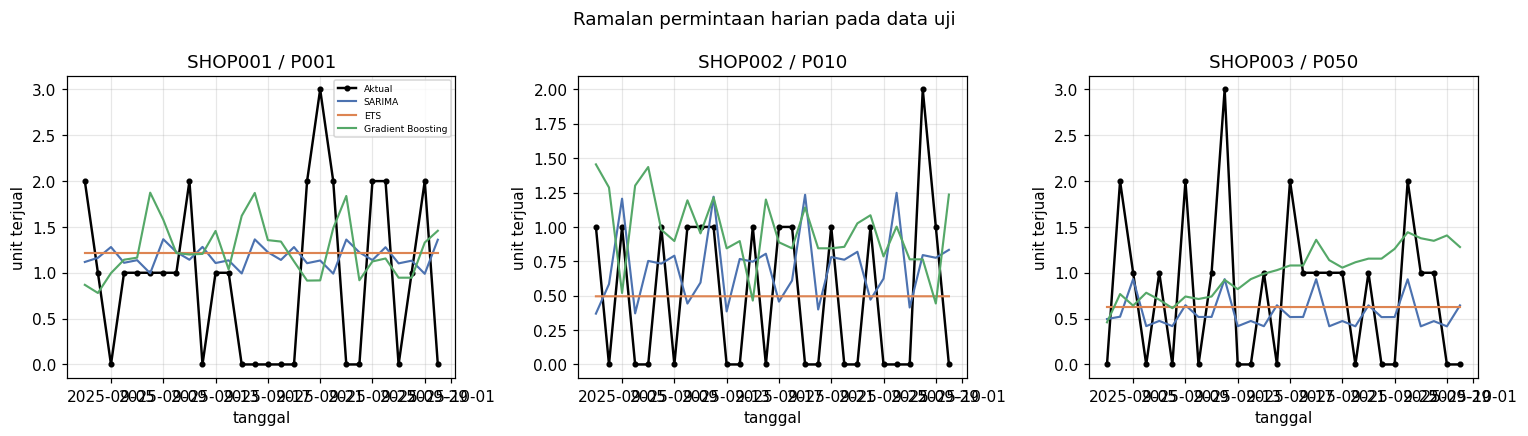

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, key in zip(axes, example_forecasts.keys()):
    data = example_forecasts[key]
    ax.plot(data["dates"], data["actual"], color="black", marker="o", ms=3, lw=1.6, label="Aktual")
    for name, color in [("SARIMA", "#4c72b0"), ("ETS", "#dd8452"), ("Gradient Boosting", "#55a868")]:
        ax.plot(data["dates"], data[name], color=color, lw=1.4, label=name)
    ax.set_title(f"{key[0]} / {key[1]}")
    ax.set_xlabel("tanggal")
    ax.set_ylabel("unit terjual")

axes[0].legend(fontsize=6)
fig.suptitle("Ramalan permintaan harian pada data uji")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "fig_2_example_forecast.png", dpi=120)
plt.show()

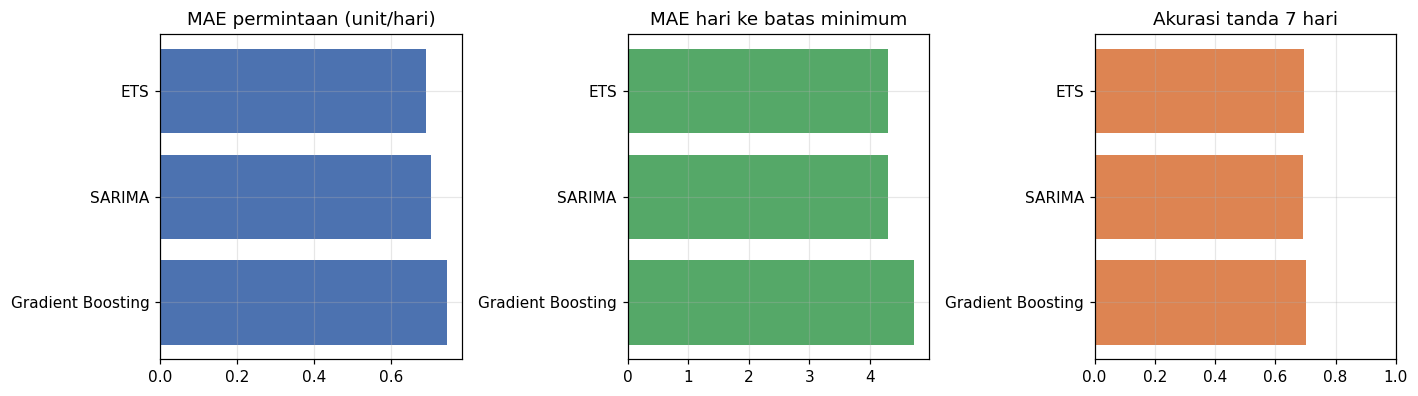

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.7))

axes[0].barh(summary.model, summary.MAE_permintaan, color="#4c72b0")
axes[0].set_title("MAE permintaan (unit/hari)")
axes[0].invert_yaxis()

axes[1].barh(summary.model, summary.MAE_hari_min, color="#55a868")
axes[1].set_title("MAE hari ke batas minimum")
axes[1].invert_yaxis()

axes[2].barh(summary.model, summary.akurasi_tanda_7hari, color="#dd8452")
axes[2].set_title("Akurasi tanda 7 hari")
axes[2].set_xlim(0, 1)
axes[2].invert_yaxis()

fig.tight_layout()
fig.savefig(OUTPUT_DIR / "fig_3_model_comparison.png", dpi=120)
plt.show()

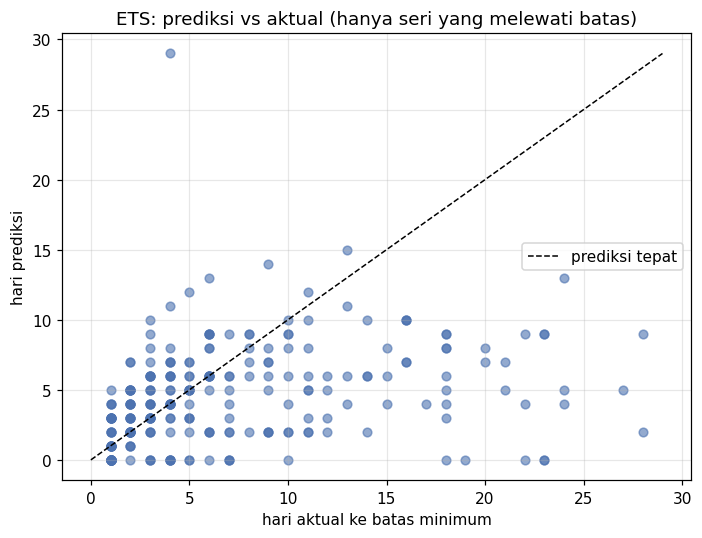

korelasi prediksi vs aktual: 0.305


In [12]:
scored = evaluation[(evaluation.model == best_name) & (evaluation.actual_days_below <= HORIZON)]

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.scatter(scored.actual_days_below, scored.pred_days_below, alpha=0.6, color="#4c72b0", s=32)
limit = HORIZON + 1
ax.plot([0, limit], [0, limit], ls="--", color="black", lw=1, label="prediksi tepat")
ax.set_xlabel("hari aktual ke batas minimum")
ax.set_ylabel("hari prediksi")
ax.set_title(f"{best_name}: prediksi vs aktual (hanya seri yang melewati batas)")
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "fig_4_predicted_vs_actual.png", dpi=120)
plt.show()

print(f"korelasi prediksi vs aktual: {scored.pred_days_below.corr(scored.actual_days_below):.3f}")

## 6. Menyimpan model terbaik ke pickle

Model terbaik dilatih ulang memakai seluruh 272 hari, satu model per seri, lalu disimpan bersama
keadaan stok terakhir. Dengan begitu sistem bisa langsung meminta waktu habis untuk setiap item.

In [13]:
full_models = {}
full_rows = []

for (outlet, item), group in stock.groupby(["Outlet", "ItemID"]):
    group = group.sort_values("Date")
    y_full = group.StockOut.to_numpy(dtype=float)
    dates_full = pd.DatetimeIndex(group.Date)
    future_dates = pd.date_range(group.Date.max() + pd.Timedelta(days=1), periods=HORIZON, freq="D")

    ets_full = ETSModel(y_full, error="add", trend="add", damped_trend=True).fit(disp=False)
    forecast_full = np.clip(np.asarray(ets_full.forecast(HORIZON), dtype=float), 0, None)

    last_row = group.iloc[-1]
    start_stock = float(last_row.ClosingStock)
    min_stock = float(last_row.MinimumStock)

    cumulative = np.cumsum(forecast_full)
    threshold_below = max(start_stock - min_stock + 1.0, 0.0)
    hit_below = np.where(cumulative >= threshold_below)[0] if threshold_below > 0 else np.array([0])
    hit_zero = np.where(cumulative >= max(start_stock, 1.0))[0]

    days_below = 0 if threshold_below == 0 else (int(hit_below[0]) + 1 if len(hit_below) else HORIZON + 1)
    days_zero = int(hit_zero[0]) + 1 if len(hit_zero) else HORIZON + 1

    full_models[f"{outlet}|{item}"] = ets_full
    full_rows.append({
        "Outlet": outlet,
        "ItemID": item,
        "last_date": last_row.Date,
        "closing_stock": start_stock,
        "min_stock": min_stock,
        "demand_forecast_28d": float(forecast_full.sum()),
        "avg_demand_daily": float(forecast_full.mean()),
        "days_to_min": days_below,
        "days_to_zero": days_zero,
    })

priority = pd.DataFrame(full_rows)

priority["status"] = pd.cut(
    priority.days_to_min,
    bins=[-1, 3, 7, 14, float("inf")],
    labels=["Kritis (<=3 hari)", "Waspada (4-7 hari)", "Pantau (8-14 hari)", "Aman (>14 hari)"],
)

print(f"model dilatih ulang pada seluruh {stock.Date.nunique()} hari untuk {len(full_models)} seri")
print()
print("Sebaran status replenishment per 30 September 2025:")
print(priority.status.value_counts().to_string())

model dilatih ulang pada seluruh 272 hari untuk 282 seri

Sebaran status replenishment per 30 September 2025:
status
Waspada (4-7 hari)    122
Kritis (<=3 hari)      98
Pantau (8-14 hari)     56
Aman (>14 hari)         6


In [14]:
bundle = {
    "name": "ETS",
    "method": "ExponentialSmoothing dengan tren aditif damping, satu model per outlet x item",
    "models": full_models,
    "horizon_days": HORIZON,
    "last_date": priority.last_date.max(),
    "config": {"error": "add", "trend": "add", "damped_trend": True},
    "state": priority[["Outlet", "ItemID", "closing_stock", "min_stock", "avg_demand_daily", "days_to_min", "days_to_zero", "status"]],
    "metrics": {record["model"]: {key: float(record[key]) for key in [
        "MAE_permintaan", "WAPE_%", "MAE_hari_min", "MAE_hari_nol", "akurasi_tanda_7hari", "dalam_1_hari", "dalam_3_hari"
    ]} for record in summary.to_dict(orient="records")},
}

with open(MODEL_PATH, "wb") as file:
    pickle.dump(bundle, file, protocol=pickle.HIGHEST_PROTOCOL)

print(f"algoritma disimpan : {bundle['name']} ({len(full_models)} model seri)")
print(f"MAE hari minimum   : {summary.loc[0, 'MAE_hari_min']:.2f} hari")
print(f"MAE permintaan     : {summary.loc[0, 'MAE_permintaan']:.3f} unit/hari")
print(f"lokasi berkas      : {MODEL_PATH}")
print(f"ukuran berkas      : {MODEL_PATH.stat().st_size / 1024 / 1024:,.1f} MB")

algoritma disimpan : ETS (282 model seri)
MAE hari minimum   : 4.30 hari
MAE permintaan     : 0.690 unit/hari
lokasi berkas      : ..\artifacts\stock_depletion\model.pkl
ukuran berkas      : 8.3 MB


## 7. Metadata

In [15]:
metadata = {
    "project": "MyVentory stock depletion and replenishment prediction",
    "target": "hari sampai ClosingStock turun di bawah MinimumStock, dan hari sampai ClosingStock = 0",
    "unit": "hari",
    "granularity": "outlet x item x hari",
    "inputs": ["Date", "Outlet", "ItemID", "OpeningStock", "StockIn", "StockOut", "ClosingStock", "MinimumStock"],
    "source": {"file": "data/Stock.csv", "rows": int(len(stock))},
    "period": {
        "start": str(stock.Date.min().date()),
        "end": str(stock.Date.max().date()),
        "days": int(stock.Date.nunique()),
    },
    "series_count": int(len(state)),
    "split": {
        "train_end": str(cutoff.date()),
        "test_days": TEST_DAYS,
        "horizon_days": HORIZON,
    },
    "data_facts": {
        "stockout_rate": round(float(stockout_rate), 4),
        "restock_rate": round(float(restock_rate), 4),
        "median_restock_gap_days": float(gap.median()),
        "median_closing_stock": float(stock.ClosingStock.median()),
        "series_below_min_in_test": int((state.actual_days_below <= HORIZON).sum()),
        "series_zero_in_test": int((state.actual_days_zero <= HORIZON).sum()),
    },
    "models": {
        record["model"]: {
            "MAE_permintaan": round(float(record["MAE_permintaan"]), 4),
            "WAPE_%": round(float(record["WAPE_%"]), 2),
            "MAE_hari_min": round(float(record["MAE_hari_min"]), 3),
            "MAE_hari_nol": round(float(record["MAE_hari_nol"]), 3),
            "akurasi_tanda_7hari": round(float(record["akurasi_tanda_7hari"]), 4),
            "dalam_1_hari": round(float(record["dalam_1_hari"]), 4),
            "dalam_3_hari": round(float(record["dalam_3_hari"]), 4),
        }
        for record in summary.to_dict(orient="records")
    },
    "baseline_rule": {"name": "stok dibagi rata-rata penjualan 28 hari", "MAE_hari_min": 4.27},
    "saved_model": {
        "file": MODEL_PATH.name,
        "algorithm": best_name,
        "series_models": int(len(full_models)),
        "horizon_days": HORIZON,
        "last_date": str(priority.last_date.max().date()),
        "mae_days_to_min": round(float(summary.loc[0, "MAE_hari_min"]), 3),
    },
    "status_rule": "Kritis <=3 hari, Waspada 4-7, Pantau 8-14, Aman >14",
    "note": (
        "Waktu habis diturunkan dari ramalan permintaan tanpa memperhitungkan kedatangan barang "
        "yang belum dijadwalkan. Karena restock di data berjalan rutin sekitar 7 hari sekali, "
        "prediksi cenderung sedikit lebih cepat dari kenyataan (bias negatif). Arah ini aman untuk "
        "pengisian stok. Stok yang benar-benar mencapai nol jauh lebih sulit diprediksi karena "
        "ditentukan oleh ketepatan waktu restock, sehingga target utama memakai batas minimum."
    ),
    "artifacts": [
        MODEL_PATH.name,
        METADATA_PATH.name,
        "replenishment_priority.csv",
        "stock_depletion_metrics.csv",
        "stock_depletion_evaluation.csv",
        "fig_1_distribution.png",
        "fig_2_example_forecast.png",
        "fig_3_model_comparison.png",
        "fig_4_predicted_vs_actual.png",
    ],
}

METADATA_PATH.write_text(json.dumps(metadata, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")
print("metadata tersimpan:", METADATA_PATH)

metadata tersimpan: ..\artifacts\stock_depletion\metadata.json


## 8. Tabel prioritas replenishment

Ini keluaran yang dipakai operasional: item mana yang harus diisi lebih dulu, diurutkan dari yang paling mendesak.

In [16]:
priority_sorted = priority.sort_values(["days_to_min", "days_to_zero", "closing_stock"]).reset_index(drop=True)

urgency_table = priority.groupby(["Outlet", "status"]).size().unstack(fill_value=0)
print("Jumlah item per status dan outlet:")
print(urgency_table.to_string())
print()
print("20 item paling mendesak:")
print(priority_sorted.head(20)[["Outlet", "ItemID", "closing_stock", "min_stock", "avg_demand_daily", "days_to_min", "days_to_zero", "status"]].round(2).to_string(index=False))

Jumlah item per status dan outlet:
status   Kritis (<=3 hari)  Waspada (4-7 hari)  Pantau (8-14 hari)  Aman (>14 hari)
Outlet                                                                             
SHOP001                 50                  37                   6                1
SHOP002                 16                  35                  39                4
SHOP003                 32                  50                  11                1

20 item paling mendesak:
 Outlet ItemID  closing_stock  min_stock  avg_demand_daily  days_to_min  days_to_zero            status
SHOP001   P012            0.0        4.0              1.21            0             1 Kritis (<=3 hari)
SHOP001   P020            0.0        3.0              1.19            0             1 Kritis (<=3 hari)
SHOP001   P029            0.0        3.0              1.11            0             1 Kritis (<=3 hari)
SHOP001   P053            0.0        4.0              1.14            0             1 Kritis (<=3 hari)

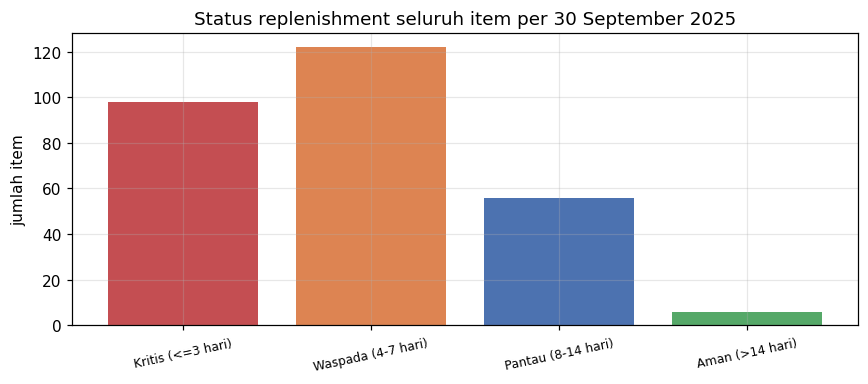

In [17]:
fig, ax = plt.subplots(figsize=(8, 3.6))
counts = priority.status.value_counts().reindex(["Kritis (<=3 hari)", "Waspada (4-7 hari)", "Pantau (8-14 hari)", "Aman (>14 hari)"])
colors = ["#c44e52", "#dd8452", "#4c72b0", "#55a868"]
ax.bar(counts.index, counts.values, color=colors)
ax.set_title("Status replenishment seluruh item per 30 September 2025")
ax.set_ylabel("jumlah item")
plt.xticks(rotation=12, fontsize=8)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "fig_5_status_summary.png", dpi=120)
plt.show()

## 9. Menyimpan tabel hasil

In [18]:
priority_sorted.to_csv(OUTPUT_DIR / "replenishment_priority.csv", index=False)
summary.round(4).to_csv(OUTPUT_DIR / "stock_depletion_metrics.csv", index=False)
evaluation.round(4).to_csv(OUTPUT_DIR / "stock_depletion_evaluation.csv", index=False)

print(f"isi folder {OUTPUT_DIR.resolve()}:")
for path in sorted(OUTPUT_DIR.iterdir()):
    print(f"  {path.name:<36} {path.stat().st_size / 1024:>10.1f} KB")

isi folder C:\Users\Radit\Politeknik Negeri Malang\Semester 5\ProjectBasedLearning_MyVentory\ML\artifacts\stock_depletion:
  fig_1_distribution.png                     36.3 KB
  fig_2_example_forecast.png                137.5 KB
  fig_3_model_comparison.png                 20.9 KB
  fig_4_predicted_vs_actual.png              47.5 KB
  fig_5_status_summary.png                   27.5 KB
  metadata.json                               2.7 KB
  model.pkl                                8533.0 KB
  replenishment_priority.csv                 25.9 KB
  stock_depletion_evaluation.csv             56.0 KB
  stock_depletion_metrics.csv                 0.3 KB


## 10. Verifikasi berkas pickle

Model dimuat ulang dari disk tanpa memakai variabel notebook, lalu dipakai menghitung waktu habis
untuk tiga item contoh.

In [19]:
with open(MODEL_PATH, "rb") as file:
    loaded = pickle.load(file)

print("berkas       :", MODEL_PATH.name)
print("algoritma    :", loaded["name"])
print("jumlah model :", len(loaded["models"]))
print("data terakhir:", pd.Timestamp(loaded["last_date"]).date())
print()

sample_keys = ["SHOP001|P001", "SHOP002|P010", "SHOP003|P050"]
for key in sample_keys:
    model = loaded["models"][key]
    forecast = np.clip(np.asarray(model.forecast(loaded["horizon_days"]), dtype=float), 0, None)
    state_row = loaded["state"][(loaded["state"].Outlet + "|" + loaded["state"].ItemID) == key].iloc[0]

    stock_now = float(state_row.closing_stock)
    min_now = float(state_row.min_stock)
    cumulative = np.cumsum(forecast)
    threshold = max(stock_now - min_now + 1.0, 0.0)
    hit = np.where(cumulative >= threshold)[0]

    days = 0 if threshold == 0 else (int(hit[0]) + 1 if len(hit) else loaded["horizon_days"] + 1)
    print(f"{key:<14} stok {stock_now:>4.0f} | minimum {min_now:>3.0f} | permintaan {forecast.mean():.2f}/hari "
          f"| perkiraan turun di bawah minimum {days} hari lagi | status {state_row.status}")

berkas       : model.pkl
algoritma    : ETS
jumlah model : 282
data terakhir: 2025-09-30

SHOP001|P001   stok    3 | minimum   5 | permintaan 1.18/hari | perkiraan turun di bawah minimum 0 hari lagi | status Kritis (<=3 hari)
SHOP002|P010   stok    2 | minimum   2 | permintaan 0.50/hari | perkiraan turun di bawah minimum 3 hari lagi | status Kritis (<=3 hari)
SHOP003|P050   stok    6 | minimum   2 | permintaan 0.73/hari | perkiraan turun di bawah minimum 7 hari lagi | status Waspada (4-7 hari)


## 11. Ringkasan

In [20]:
print("RINGKASAN HASIL")
print("-" * 66)
print("target          : waktu sampai stok turun di bawah minimum dan sampai stok nol")
print(f"data            : {len(stock):,} baris, {len(state)} seri outlet x item, {stock.Date.nunique()} hari")
print(f"data uji        : {TEST_DAYS} hari terakhir tiap seri")
print()
print(summary[["model", "MAE_permintaan", "WAPE_%", "MAE_hari_min", "MAE_hari_nol", "akurasi_tanda_7hari"]].round(3).to_string(index=False))
print()
print(f"model terbaik   : {best_name}")
print(f"MAE hari minimum: {summary.loc[0, 'MAE_hari_min']:.2f} hari (aturan sederhana: 4.27 hari)")
print(f"akurasi tanda 7 hari: {summary.loc[0, 'akurasi_tanda_7hari']:.3f}")
print()
print("status per 30 September 2025:")
for label, count in counts.items():
    print(f"  {label:<20} {count:>3} item")
print()
print("berkas keluaran:")
for path in sorted(OUTPUT_DIR.iterdir()):
    print("  ", path.name)

RINGKASAN HASIL
------------------------------------------------------------------
target          : waktu sampai stok turun di bawah minimum dan sampai stok nol
data            : 76,704 baris, 282 seri outlet x item, 272 hari
data uji        : 28 hari terakhir tiap seri

            model  MAE_permintaan  WAPE_%  MAE_hari_min  MAE_hari_nol  akurasi_tanda_7hari
              ETS           0.690  95.166         4.299         7.095                0.695
           SARIMA           0.704  97.117         4.303         7.142                0.691
Gradient Boosting           0.746 102.908         4.737         7.230                0.702

model terbaik   : ETS
MAE hari minimum: 4.30 hari (aturan sederhana: 4.27 hari)
akurasi tanda 7 hari: 0.695

status per 30 September 2025:
  Kritis (<=3 hari)     98 item
  Waspada (4-7 hari)   122 item
  Pantau (8-14 hari)    56 item
  Aman (>14 hari)        6 item

berkas keluaran:
   fig_1_distribution.png
   fig_2_example_forecast.png
   fig_3_model_compar

## Export model ke API (berversion)

Model disalin ke `API/artifacts/stock_depletion/1.0.0/` sehingga versi lama tetap tersimpan dan bisa
dibandingkan. Versi juga ditulis ke `metadata.json` sebagai `model_version`.

In [21]:
import shutil

NOTEBOOK_NAME = "stock_depletion_forecast"
NOTEBOOK_VERSION = "1.0.0"
API_DIR = Path("..").resolve().parent / "API" / "artifacts" / "stock_depletion" / NOTEBOOK_VERSION
API_DIR.mkdir(parents=True, exist_ok=True)

api_metadata = json.loads((OUTPUT_DIR / "metadata.json").read_text(encoding="utf-8"))
api_metadata.update({
    "model_id": "stock_depletion",
    "model_version": NOTEBOOK_VERSION,
    "source_notebook": NOTEBOOK_NAME,
})

shutil.copy2(OUTPUT_DIR / "model.pkl", API_DIR / "model.pkl")
(API_DIR / "metadata.json").write_text(
    json.dumps(api_metadata, indent=2, ensure_ascii=False) + "\n",
    encoding="utf-8",
)

print(f"{NOTEBOOK_NAME} versi {NOTEBOOK_VERSION} diekspor ke:")
print(" ", API_DIR)
for path in sorted(API_DIR.iterdir()):
    print(f"   {path.name:<20} {path.stat().st_size / 1024:>9.1f} KB")

stock_depletion_forecast versi 1.0.0 diekspor ke:
  C:\Users\Radit\Politeknik Negeri Malang\Semester 5\ProjectBasedLearning_MyVentory\API\artifacts\stock_depletion\1.0.0
   metadata.json              2.8 KB
   model.pkl               8533.0 KB
